In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association


In [2]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

sorted_crosstab = crosstab_result.sort_values(by=True, ascending=False)

sorted_crosstab.head(10)



isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
Beauty,19010,302
Pet Supplies,9152,285
Arts & Crafts,9319,230
Women,17559,213


The category where the best-seller status is most prevalent is Grocery, followed by Health & Personal Care and Baby.

In [5]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

We can observe a strong dependence between the two variables using the Chi-Square test. A Chi-Square value this large demonstrates that the relationship between the two variables is significant. The p-value equal to 0 also indicates that the null hypothesis is nonexistent.

In [6]:
association(crosstab_result, method="cramer")

0.1222829439760564

The result of Cramér's V is 0.1222, which is very low, indicating a weak relationship between the two variables, despite the result of the Chi-Square test. We can therefore conclude that the variables are not independent, but their relationship is weak.

<Axes: xlabel='category'>

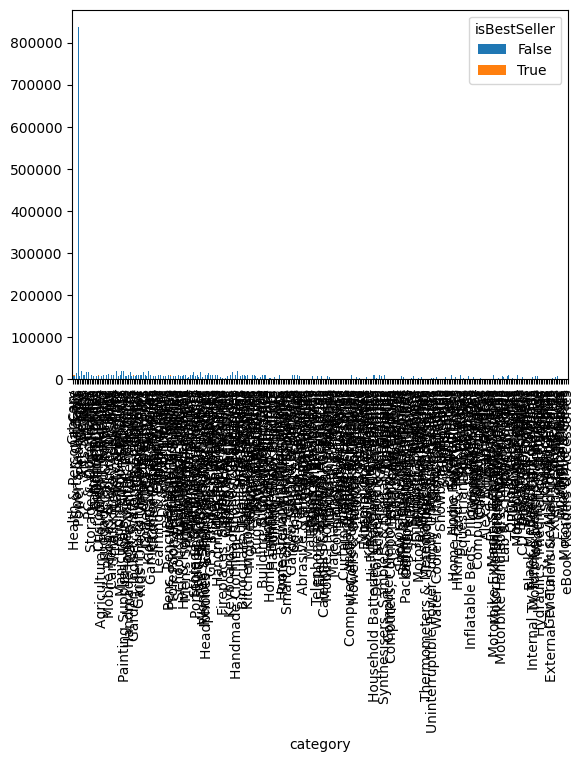

In [7]:
sorted_crosstab.plot(kind="bar", stacked=True)



In [8]:
def tukeys_test_outliers(df):
    """
    Identify outliers in a dataset using Tukey's fences method.

    Parameters:
        data (pd.Series): A pandas Series containing numerical data.

    Returns:
        pd.Series: A Series containing the outliers.
    """
    # Calculate the first and third quartiles
    Q1 = df["price"].quantile(0.25)
    Q3 = df["price"].quantile(0.75)
    IQR = Q3 - Q1  # Interquartile range

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
    return df_no_outliers


In [9]:
data_series = tukeys_test_outliers(df)
data_series.shape

(2115963, 9)

In [10]:
df.shape

(2443651, 9)

In [14]:
top_categories = df['category'].value_counts().head(20).index
filtered_df = df[df['category'].isin(top_categories)]

In [ ]:
filtered_df.head()

/var/folders/rr/vnzh8t7108l7nn8z8dj1wrdh0000gn/T/ipykernel_56170/3378754525.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=filtered_df, x='category', y='price', palette="coolwarm", legend=False)


<Axes: xlabel='category', ylabel='price'>

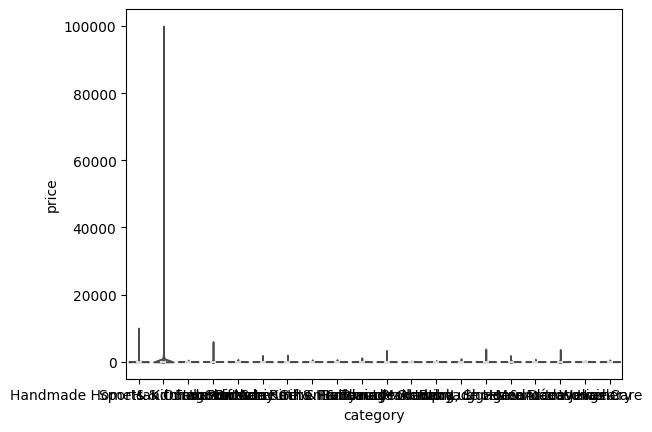

In [18]:
sns.violinplot(data=filtered_df, x='category', y='price', palette="coolwarm", legend=False)

/var/folders/rr/vnzh8t7108l7nn8z8dj1wrdh0000gn/T/ipykernel_56170/1088015370.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='category', y='price', data=filtered_df, palette="muted")


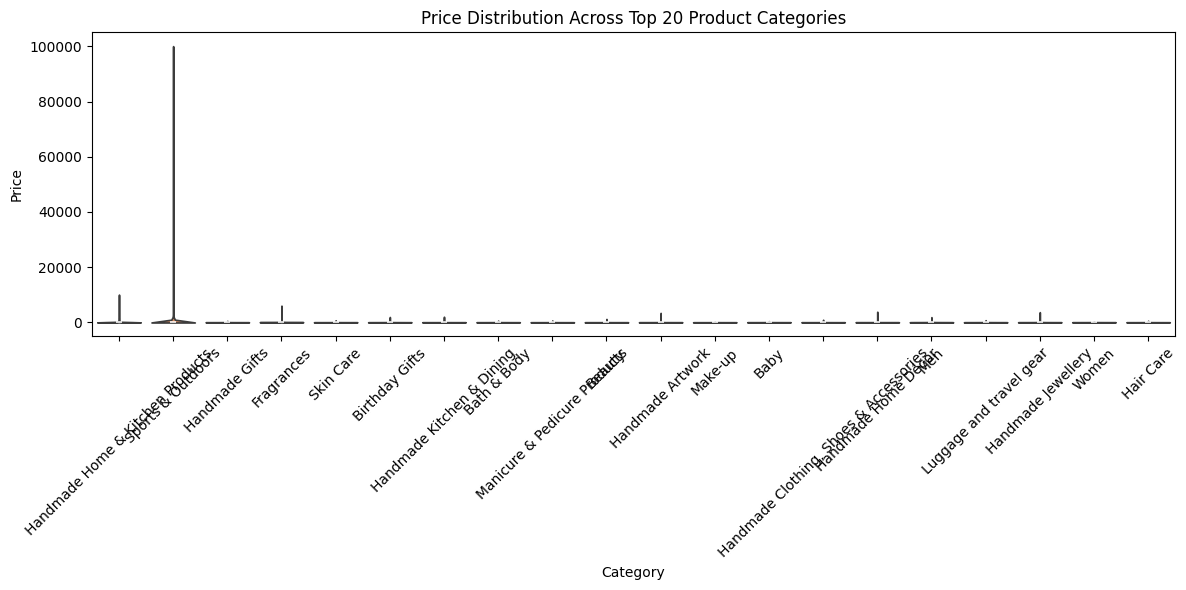

In [16]:
plt.figure(figsize=(12, 6))
sns.violinplot(x='category', y='price', data=filtered_df, palette="muted")
plt.xticks(rotation=45)
plt.title("Price Distribution Across Top 20 Product Categories")
plt.xlabel("Category")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [20]:
top_categories_2= df['category'].value_counts().head(10).index
filtered_df_2 = df[df['category'].isin(top_categories)]

# Step 1: Group by category and calculate the average price
average_prices_top10 = filtered_df_2.groupby('category')['price'].mean()

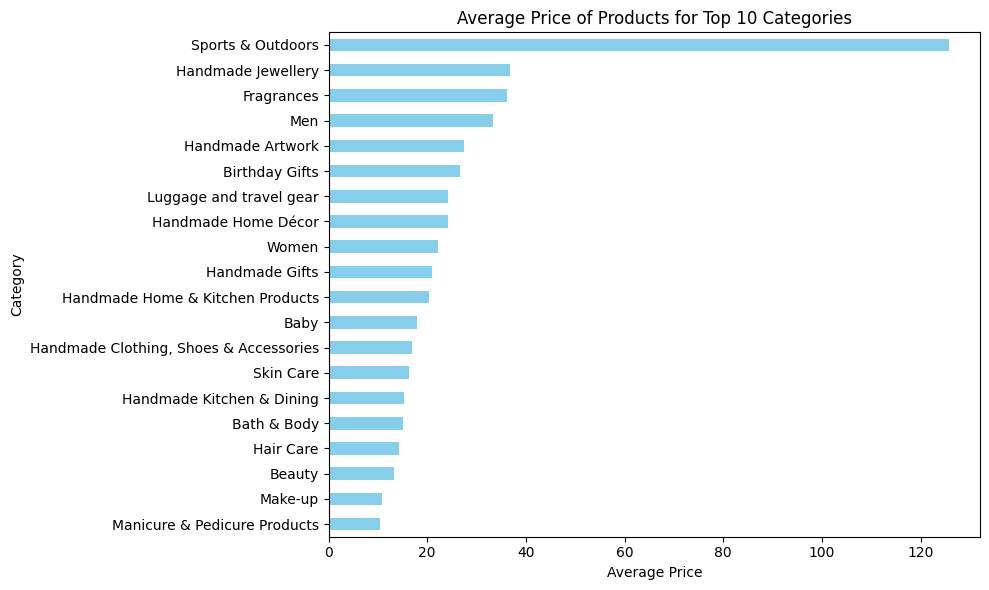

In [24]:
plt.figure(figsize=(10, 6))
average_prices_top10.sort_values().plot(kind='barh', color="skyblue")
plt.title("Average Price of Products for Top 10 Categories")
plt.xlabel("Average Price")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [29]:
average_prices_full = df.groupby('category')['price'].mean()
highest_avg_category = average_prices_full.idxmax()
highest_avg_value = average_prices_full.max()

highest_avg_category, highest_avg_value


('Laptops', np.float64(1087.987826986755))

/var/folders/rr/vnzh8t7108l7nn8z8dj1wrdh0000gn/T/ipykernel_56170/3183457826.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_df_2, x='stars', y='category', palette="coolwarm")


<Axes: xlabel='stars', ylabel='category'>

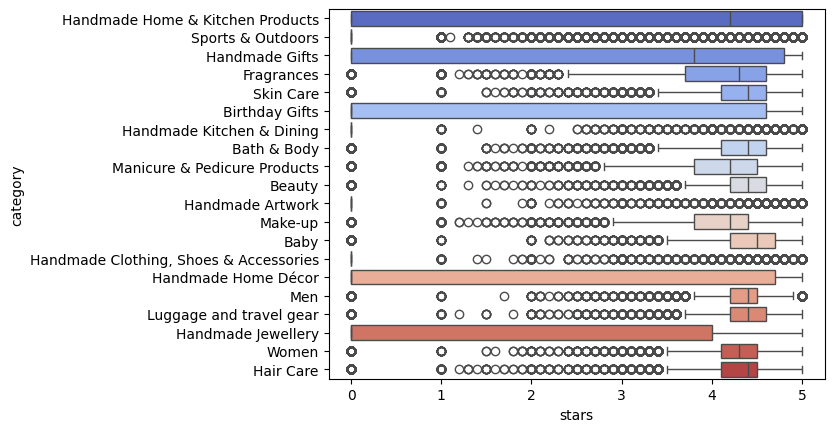

In [31]:
sns.boxplot(data=filtered_df_2, x='stars', y='category', palette="coolwarm")

In [32]:
median_ratings = df.groupby('category')['stars'].median().sort_values(ascending=False)
highest_median_category = median_ratings.idxmax()
highest_median_value = median_ratings.max()

highest_median_category, highest_median_value

('Computer Memory', np.float64(4.7))

In [34]:
from scipy.stats import pearsonr

correlation_coef, _ = pearsonr(df['price'], df['stars'])
print("Correlation Coefficient:", correlation_coef)

Correlation Coefficient: -0.12490673262319063


Their is a weak negative linear correlation between price and rating.

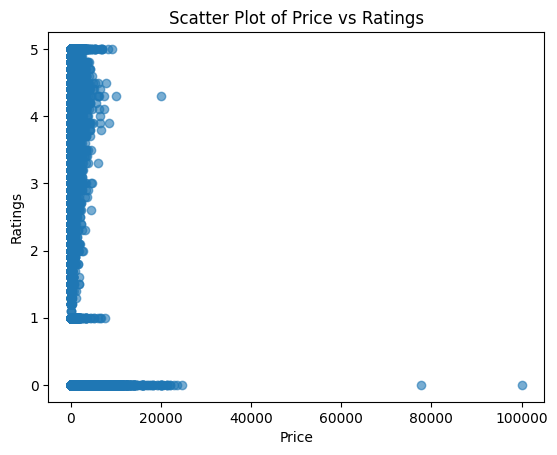

In [35]:
import matplotlib.pyplot as plt

plt.scatter(df['price'], df['stars'], alpha=0.6)
plt.title('Scatter Plot of Price vs Ratings')
plt.xlabel('Price')
plt.ylabel('Ratings')
plt.show()


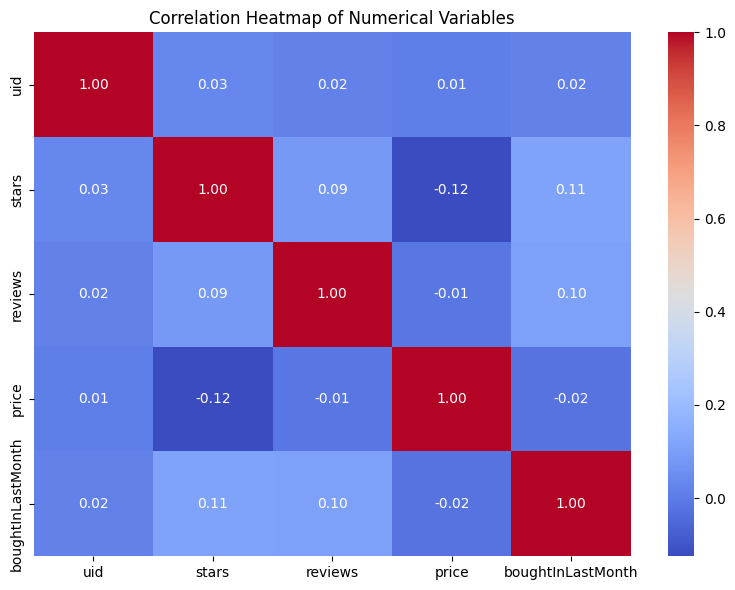

In [39]:
numerical_df = df.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numerical_df.corr()

# Create the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

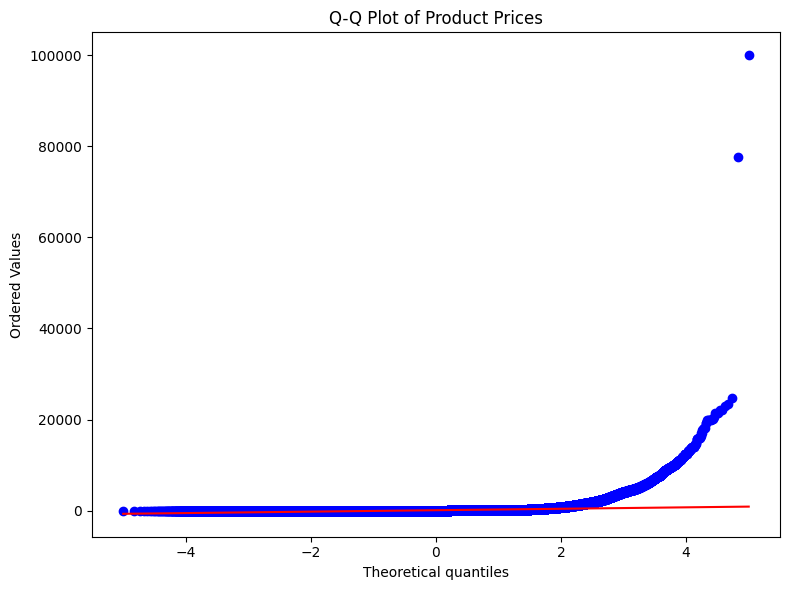

In [ ]:
from scipy import stats

plt.figure(figsize=(8, 6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title('Q-Q Plot of Product Prices')
plt.tight_layout()
plt.show()